# Draft 2 Results figures

All four figures use the **frozen 110-participant preprocessing** and **revised Experiment 1 primary analysis**. The 107-participant sensitivity analysis and archived original experiment are excluded. Experiment 2 supplies the five nested-CV repetition AUCs (each is a mean of five outer-fold AUCs).

This notebook only reads saved QC, predictions, metrics and settings. It does not fit models, rerun cross-validation, recompute bootstrap intervals, or change preprocessing. Run all cells using the project `.venv` kernel. Exports are written only to `outputs/draft2_figures/` as 300-dpi PNGs and vector PDFs.

The external AUC interval is conditional on the fitted model; it is not a pointwise ROC band. Internal repetition variation is split variability, not a confidence interval. Dataset membership does not establish person-level or acquisition-cohort independence.

In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "HANDOFF.md").is_file() and (p / "outputs/experiment_1_revised").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Run this notebook inside the nsci270-final project.")
FROZEN = PROJECT / "outputs/frozen_preprocessing_2026-11-16_124625_EST"
EXP1 = PROJECT / "outputs/experiment_1_revised"
EXP2 = PROJECT / "outputs/experiment_2"
OUTPUT = PROJECT / "outputs/draft2_figures"
ANALYSIS = "primary_110"
LABELS = {"Control": 0, "Psychosis": 1}

# Verify the frozen inputs and their identity in both experiments before plotting.
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

manifest = json.loads((FROZEN / "sha256_manifest.json").read_text())
frozen_files = ["participant_inventory.csv", "participant_qc.csv", "preprocessing_settings.json",
                "resting-task-1_features.csv", "resting-task-2_features.csv"]
for name in frozen_files:
    relative = f"master_preprocessing/{name}"
    assert sha256(FROZEN / relative) == manifest["sha256"][relative], f"Frozen input changed: {name}"
settings = json.loads((FROZEN / "master_preprocessing/preprocessing_settings.json").read_text())
exp1_settings = json.loads((EXP1 / "experiment_settings.json").read_text())
exp2_settings = json.loads((EXP2 / "experiment_settings.json").read_text())
selection = json.loads((EXP1 / "selected_settings.json").read_text())
for relative, digest in exp1_settings["input_sha256"][ANALYSIS].items():
    assert sha256(PROJECT / "outputs" / relative) == digest, f"Experiment 1 input changed: {relative}"
for relative, digest in exp2_settings["input_sha256"].items():
    assert sha256(PROJECT / relative) == digest, f"Experiment 2 input changed: {relative}"
assert settings["minimum_usable_seconds"] == 60
assert exp1_settings["label_codes"] == exp2_settings["label_codes"] == LABELS

inventory = pd.read_csv(FROZEN / "master_preprocessing/participant_inventory.csv")
qc = pd.read_csv(FROZEN / "master_preprocessing/participant_qc.csv", keep_default_na=False)
all_predictions = pd.read_csv(EXP1 / "test_predictions.csv")
all_metrics = pd.read_csv(EXP1 / "test_metrics.csv", keep_default_na=False)
# Both files also contain sensitivity_baseline_107. Never combine their rows.
predictions = all_predictions.loc[all_predictions.analysis_version.eq(ANALYSIS)].copy()
primary_metrics = all_metrics.loc[all_metrics.analysis_version.eq(ANALYSIS)]
assert len(primary_metrics) == 1, "Expected one primary metrics row"
metrics = primary_metrics.iloc[0]
repeats = pd.read_csv(EXP2 / "nested_cv_repeat_metrics.csv").sort_values("repeat")
folds = pd.read_csv(EXP2 / "nested_cv_fold_metrics.csv")
summary = pd.read_csv(EXP2 / "summary_metrics.csv").set_index("metric")
input_paths = [FROZEN / "master_preprocessing" / name for name in frozen_files] + [
    EXP1 / name for name in ["experiment_settings.json", "selected_settings.json", "test_predictions.csv", "test_metrics.csv"]
] + [EXP2 / name for name in ["experiment_settings.json", "nested_cv_repeat_metrics.csv", "nested_cv_fold_metrics.csv", "summary_metrics.csv"]]
input_hashes = {str(p.relative_to(PROJECT)): sha256(p) for p in input_paths}

## Validate saved results

Counts and plotted statistics below come from the saved tables. Assertions compare them with the Draft 2 targets and the saved experiment settings; any disagreement stops execution before figure exports. The saved AUC interval is reused without bootstrapping again. No repeated participant predictions are pooled.

In [2]:
keys = ["dataset", "participant_id"]
assert not inventory.duplicated(keys).any() and not qc.duplicated(keys).any()
assert pd.api.types.is_bool_dtype(qc.included), "QC inclusion must be Boolean"
joined = inventory[keys + ["diagnosis"]].merge(qc, on=keys, how="outer", suffixes=("_inventory", ""), indicator=True, validate="one_to_one")
assert joined["_merge"].eq("both").all()
assert joined.diagnosis_inventory.eq(joined.diagnosis).all()
assert set(joined.diagnosis) == set(LABELS)
assert set(joined.dataset) == {"resting-task-1", "resting-task-2"}
assert not joined.participant_id.duplicated().any()
excluded = joined.loc[~joined.included]
assert excluded.exclusion_reason.eq("fewer than 60 usable seconds after fixed artifact rejection").all()
assert excluded.usable_seconds.lt(settings["minimum_usable_seconds"]).all()
assert joined.loc[joined.included, "usable_seconds"].ge(settings["minimum_usable_seconds"]).all()

flow_rows = []
for dataset, group in joined.groupby("dataset", sort=True):
    retained = group.loc[group.included]
    flow_rows.append({"dataset": dataset, "initial": len(group),
        "initial_psychosis": int(group.diagnosis.eq("Psychosis").sum()),
        "initial_control": int(group.diagnosis.eq("Control").sum()),
        "excluded": int((~group.included).sum()), "retained": len(retained),
        "retained_psychosis": int(retained.diagnosis.eq("Psychosis").sum()),
        "retained_control": int(retained.diagnosis.eq("Control").sum()),
        "exclusion_percent": 100*(~group.included).mean()})
flow = pd.DataFrame(flow_rows).set_index("dataset")
expected_counts = {"resting-task-1": [82, 50, 32, 7, 75, 46, 29],
                   "resting-task-2": [61, 31, 30, 26, 35, 21, 14]}
count_columns = ["initial", "initial_psychosis", "initial_control", "excluded", "retained", "retained_psychosis", "retained_control"]
for dataset, expected in expected_counts.items():
    assert flow.loc[dataset, count_columns].tolist() == expected, f"Unexpected counts: {dataset}"
assert flow.retained.sum() == 110
assert [f"{v:.1f}" for v in flow.exclusion_percent] == ["8.5", "42.6"]

assert predictions.dataset.eq("resting-task-2").all() and predictions.participant_id.is_unique
assert len(predictions) == int(metrics.test_n) == 35
included_test = qc.loc[qc.dataset.eq("resting-task-2") & qc.included].set_index("participant_id")
assert set(predictions.participant_id) == set(included_test.index)
assert predictions.diagnosis.tolist() == included_test.loc[predictions.participant_id, "diagnosis"].tolist()
y_true = predictions.true_label.to_numpy()
probability = predictions.probability_psychosis.to_numpy()
assert np.array_equal(y_true, predictions.diagnosis.map(LABELS).to_numpy())
assert np.isfinite(probability).all() and ((0 <= probability) & (probability <= 1)).all()
threshold = float(selection["threshold"])
assert threshold == exp1_settings["threshold"] == exp2_settings["threshold"] == 0.50
assert selection["selected"][ANALYSIS] == exp1_settings["selected"][ANALYSIS]
y_predicted = (probability >= threshold).astype(int)
assert np.array_equal(y_predicted, predictions.predicted_label.to_numpy())

fpr, tpr, _ = roc_curve(y_true, probability, drop_intermediate=False)
external_auc = float(roc_auc_score(y_true, probability))
ci_low, ci_high = float(metrics.roc_auc_ci_low), float(metrics.roc_auc_ci_high)
assert np.isclose(external_auc, float(metrics.roc_auc), atol=1e-12, rtol=0)
assert 0 <= ci_low <= external_auc <= ci_high <= 1
assert [f"{v:.3f}" for v in [external_auc, ci_low, ci_high]] == ["0.497", "0.289", "0.704"]
bootstrap = exp1_settings["bootstrap"]
assert bootstrap["resamples"] == 5000 and bootstrap["stratified_by"] == "diagnosis"
assert "fixed predictions" in bootstrap["interval"] and "no refitting" in bootstrap["interval"]

matrix = confusion_matrix(y_true, y_predicted, labels=[0, 1])
assert np.array_equal(matrix, [[2, 12], [1, 20]])
tn, fp, fn, tp = matrix.ravel()
sensitivity, specificity = tp/(tp+fn), tn/(tn+fp)
balanced_accuracy, accuracy = (sensitivity+specificity)/2, (tn+tp)/matrix.sum()
assert matrix.sum() == 35 and matrix.sum(axis=1).tolist() == [14, 21]
assert y_predicted.sum() == 32 and sensitivity == 20/21 and specificity == 2/14 and accuracy == 22/35
for name, value in {"sensitivity": sensitivity, "specificity": specificity,
                    "balanced_accuracy": balanced_accuracy, "accuracy": accuracy,
                    "true_negative": tn, "false_positive": fp, "false_negative": fn, "true_positive": tp}.items():
    assert np.isclose(value, float(metrics[name]), atol=1e-12, rtol=0), name
assert f"{balanced_accuracy:.3f}" == "0.548"

# Each repetition estimate is a mean of its five fold AUCs, not a pooled-prediction AUC.
assert repeats.repeat.tolist() == [1, 2, 3, 4, 5] and repeats.seed.tolist() == [101, 202, 303, 404, 505]
assert not folds.duplicated(["repeat", "outer_fold"]).any()
assert folds.groupby("repeat").size().eq(5).all()
assert np.allclose(repeats.internal_auc, folds.groupby("repeat").outer_fold_auc.mean().loc[repeats.repeat], atol=1e-12, rtol=0)
repeat_aucs = repeats.internal_auc.to_numpy()
assert np.isfinite(repeat_aucs).all() and ((repeat_aucs >= 0) & (repeat_aucs <= 1)).all()
assert [f"{v:.3f}" for v in repeat_aucs] == ["0.582", "0.631", "0.659", "0.581", "0.621"]
internal_auc = float(repeat_aucs.mean())
gap = internal_auc - external_auc
assert f"{internal_auc:.3f}" == "0.615" and f"{gap:.3f}" == "0.118"
for key, value in {"internal_auc": internal_auc, "external_auc": external_auc, "gap": gap}.items():
    assert np.isclose(value, exp2_settings["results"][key], atol=1e-12, rtol=0), key
assert np.allclose([ci_low, ci_high], exp2_settings["results"]["external_ci"], atol=1e-12, rtol=0)
assert np.allclose(summary.loc["roc_auc"].to_numpy(dtype=float), [internal_auc, external_auc, gap], atol=1e-12, rtol=0)
assert np.allclose(repeats.gap_vs_external, repeat_aucs-external_auc, atol=1e-12, rtol=0)
assert not np.isclose(internal_auc, selection["selected"][ANALYSIS]["mean_cv_auc"])

display(flow)
display(pd.DataFrame({"metric": ["External AUC", "CI lower", "CI upper", "Sensitivity", "Specificity", "Balanced accuracy", "Accuracy", "Internal mean AUC", "Internal − external"],
                      "value": [external_auc, ci_low, ci_high, sensitivity, specificity, balanced_accuracy, accuracy, internal_auc, gap]}))
print("All Draft 2 targets and saved-result consistency checks passed.")

,initial,initial_psychosis,initial_control,excluded,retained,retained_psychosis,retained_control,exclusion_percent
dataset,,,,,,,,
resting-task-1,82,50,32,7,75,46,29,8.536585
resting-task-2,61,31,30,26,35,21,14,42.622951


,metric,value
0,External AUC,0.496599
1,CI lower,0.289116
2,CI upper,0.704082
3,Sensitivity,0.952381
4,Specificity,0.142857
5,Balanced accuracy,0.547619
6,Accuracy,0.628571
7,Internal mean AUC,0.614756
8,Internal − external,0.118157


All Draft 2 targets and saved-result consistency checks passed.


In [3]:
BLUE = "#25618B"
ORANGE = "#B75B26"
INK = "#24313C"
GRAY = "#737C84"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.labelsize": 11, "axes.titlesize": 12,
    "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.dpi": 120,
})
OUTPUT.mkdir(parents=True, exist_ok=True)
exported = []


def save_and_show(fig, stem):
    for extension in ["png", "pdf"]:
        destination = OUTPUT / f"{stem}.{extension}"
        fig.savefig(destination, dpi=300, bbox_inches="tight", pad_inches=0.12, facecolor="white")
        exported.append(destination)
    plt.show()
    plt.close(fig)

## Figure 1

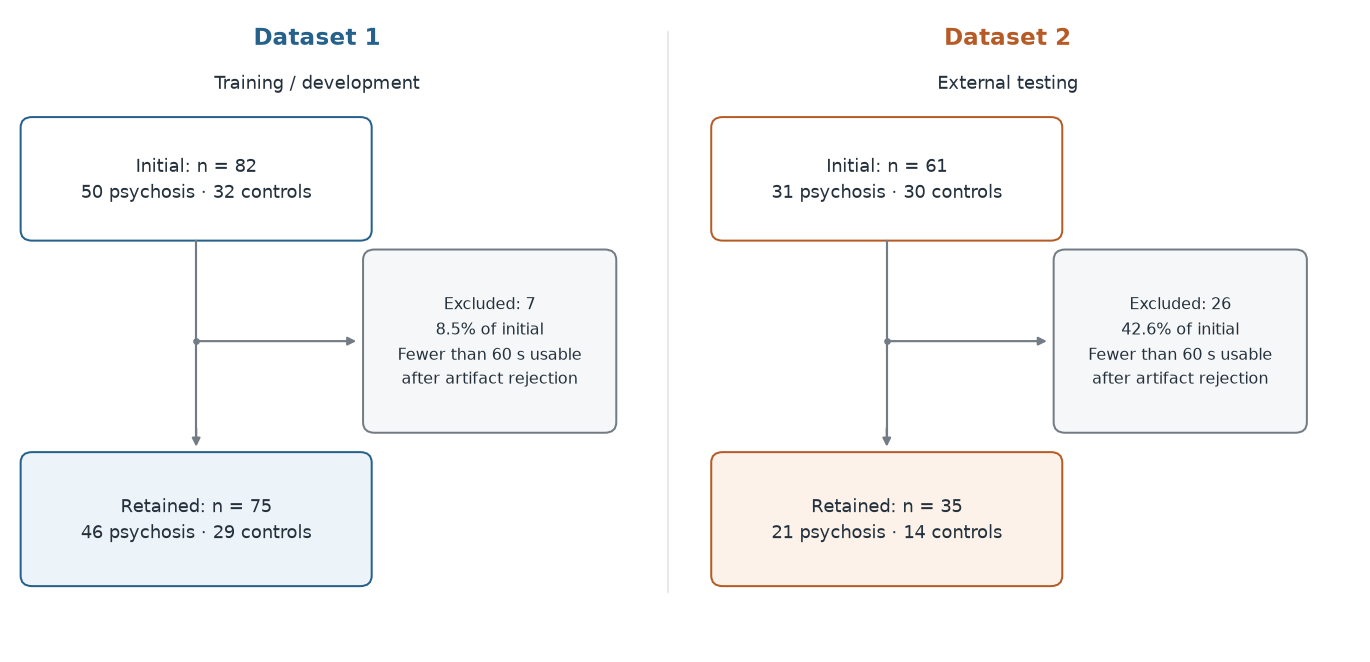

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 5.6))
ax.set(xlim=(0, 11.7), ylim=(0, 6.1))
ax.axis("off")


def flow_box(cx, cy, width, height, text, color, fill, fontsize=10.5):
    ax.add_patch(FancyBboxPatch((cx-width/2, cy-height/2), width, height,
        boxstyle="round,pad=0.05,rounding_size=0.10", linewidth=1.2, edgecolor=color, facecolor=fill))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fontsize, linespacing=1.6)


for i, (dataset, row) in enumerate(flow.iterrows()):
    offset = i*6.0
    center, branch = 1.6+offset, 4.15+offset
    color = BLUE if i == 0 else ORANGE
    fill = "#EDF4F9" if i == 0 else "#FCF2E9"
    role = "Training / development" if i == 0 else "External testing"
    ax.text(2.65+offset, 5.78, f"Dataset {i+1}", ha="center", fontsize=14, fontweight="bold", color=color)
    ax.text(2.65+offset, 5.36, role, ha="center", fontsize=11)
    flow_box(center, 4.50, 2.95, 1.08,
             f"Initial: n = {int(row.initial)}\n{int(row.initial_psychosis)} psychosis · {int(row.initial_control)} controls", color, "white")
    # The side arrow branches off the initial-to-retained path.
    ax.plot([center, center], [3.91, 2.02], color=GRAY, linewidth=1.3)
    ax.annotate("", xy=(center, 1.91), xytext=(center, 2.15), arrowprops={"arrowstyle": "-|>", "color": GRAY, "lw": 1.3})
    ax.plot([center], [2.95], "o", color=GRAY, markersize=3)
    ax.annotate("", xy=(branch-1.13, 2.95), xytext=(center, 2.95), arrowprops={"arrowstyle": "-|>", "color": GRAY, "lw": 1.3})
    flow_box(branch, 2.95, 2.10, 1.65,
             f"Excluded: {int(row.excluded)}\n{row.exclusion_percent:.1f}% of initial\nFewer than 60 s usable\nafter artifact rejection",
             GRAY, "#F6F7F8", fontsize=9.5)
    flow_box(center, 1.25, 2.95, 1.18,
             f"Retained: n = {int(row.retained)}\n{int(row.retained_psychosis)} psychosis · {int(row.retained_control)} controls", color, fill)
ax.plot([5.7, 5.7], [0.55, 5.9], color="#E1E5E9", linewidth=1)
fig.tight_layout(pad=1)
save_and_show(fig, "figure_1_participant_flow")

Participant inclusion following preprocessing and quality control. Dataset 1 retained 75 participants and Dataset 2 retained 35. All participant exclusions resulted from insufficient usable recording duration after artifact rejection.

## Figure 2

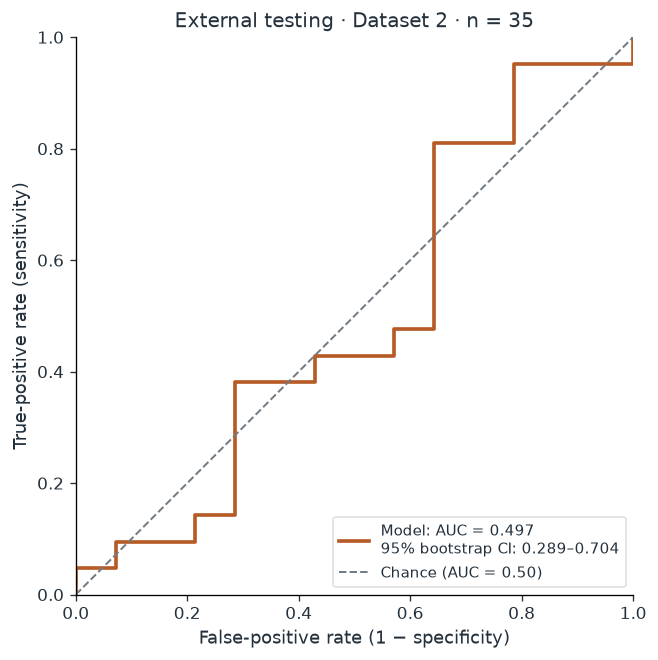

In [5]:
fig, ax = plt.subplots(figsize=(5.9, 5.6))
ax.plot(fpr, tpr, color=ORANGE, linewidth=2.2,
        label=f"Model: AUC = {external_auc:.3f}\n95% bootstrap CI: {ci_low:.3f}–{ci_high:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color=GRAY, linewidth=1.2, label="Chance (AUC = 0.50)")
ax.set(xlabel="False-positive rate (1 − specificity)", ylabel="True-positive rate (sensitivity)",
       xlim=(0, 1), ylim=(0, 1), title=f"External testing · Dataset 2 · n = {len(predictions)}")
ax.set_aspect("equal", adjustable="box")
ax.set_xticks(np.linspace(0, 1, 6)); ax.set_yticks(np.linspace(0, 1, 6))
ax.legend(loc="lower right", fontsize=9, frameon=True, facecolor="white", framealpha=1, edgecolor="#DDE2E5")
# The saved limits describe AUC uncertainty, not uncertainty along the ROC curve.
fig.tight_layout()
save_and_show(fig, "figure_2_external_roc")

Receiver operating characteristic curve for classification in Dataset 2. External ROC-AUC was 0.497 (95% bootstrap confidence interval: 0.289–0.704). The interval was calculated using 5,000 stratified participant-level bootstrap resamples with fixed model predictions.

## Figure 3

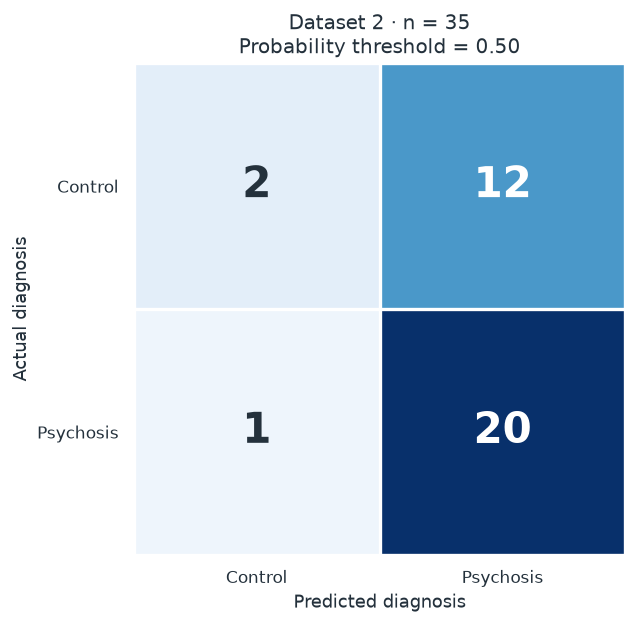

In [6]:
fig, ax = plt.subplots(figsize=(5.7, 5.3))
# Draw vector cells so the PDF remains fully vector.
ax.pcolormesh(np.arange(3)-.5, np.arange(3)-.5, matrix,
              cmap="Blues", vmin=0, vmax=matrix.max(), shading="flat", rasterized=False)
ax.set(xlim=(-.5, 1.5), ylim=(1.5, -.5), aspect="equal")
for (row, column), count in np.ndenumerate(matrix):
    ax.text(column, row, str(int(count)), ha="center", va="center", fontsize=25, fontweight="bold",
            color="white" if count > matrix.max()/2 else INK)
ax.set_xticks([0, 1], ["Control", "Psychosis"])
ax.set_yticks([0, 1], ["Control", "Psychosis"])
ax.set(xlabel="Predicted diagnosis", ylabel="Actual diagnosis",
       title=f"Dataset 2 · n = {matrix.sum()}\nProbability threshold = {threshold:.2f}")
ax.set_xticks(np.arange(-.5, 2, 1), minor=True); ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0, pad=9)
for spine in ax.spines.values(): spine.set_visible(False)
fig.tight_layout()
save_and_show(fig, "figure_3_confusion_matrix")

Confusion matrix for Dataset 2 at a predicted-probability threshold of 0.50. The model correctly classified 20 participants with psychosis and 2 controls, while misclassifying 12 controls and 1 participant with psychosis.

## Figure 4

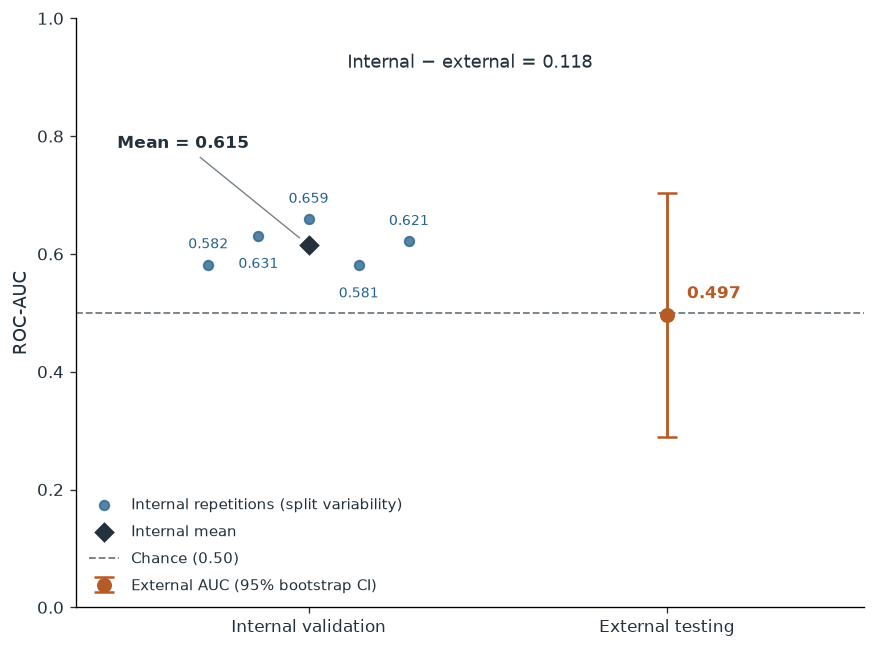

In [7]:
fig, ax = plt.subplots(figsize=(7.4, 5.5))
offsets = np.linspace(-.28, .28, len(repeat_aucs))  # deterministic spacing; no statistical meaning
ax.scatter(offsets, repeat_aucs, s=34, color=BLUE, alpha=.78, zorder=3, label="Internal repetitions (split variability)")
for i, (x, value) in enumerate(zip(offsets, repeat_aucs)):
    ax.annotate(f"{value:.3f}", (x, value), xytext=(0, 12 if i % 2 == 0 else -17),
                textcoords="offset points", ha="center", va="center", fontsize=8.5, color=BLUE)
ax.scatter([0], [internal_auc], s=95, marker="D", color=INK, edgecolor="white", linewidth=1,
           zorder=4, label="Internal mean")
ax.annotate(f"Mean = {internal_auc:.3f}", (0, internal_auc), xytext=(-.35, .78),
            ha="center", fontsize=10, fontweight="bold",
            arrowprops={"arrowstyle": "-", "color": GRAY, "lw": .8, "shrinkB": 7})
ax.errorbar([1], [external_auc], yerr=[[external_auc-ci_low], [ci_high-external_auc]],
            fmt="o", markersize=8, color=ORANGE, elinewidth=1.7, capsize=6, capthick=1.5,
            zorder=3, label="External AUC (95% bootstrap CI)")
ax.annotate(f"{external_auc:.3f}", (1, external_auc), xytext=(12, 10),
            textcoords="offset points", fontsize=10, fontweight="bold", color=ORANGE)
ax.axhline(.5, linestyle="--", color=GRAY, linewidth=1.1, zorder=1, label="Chance (0.50)")
ax.text(.5, .94, f"Internal − external = {gap:.3f}", transform=ax.transAxes,
        ha="center", va="top", fontsize=11)
ax.set(xticks=[0, 1], xticklabels=["Internal validation", "External testing"],
       ylabel="ROC-AUC", xlim=(-.65, 1.55), ylim=(0, 1))
ax.set_yticks(np.linspace(0, 1, 6))
ax.legend(loc="lower left", fontsize=9, frameon=False, labelspacing=.8)
fig.tight_layout()
save_and_show(fig, "figure_4_internal_external_auc")

Internal and external classification performance. Mean internal ROC-AUC from repeated nested cross-validation was 0.615, compared with 0.497 during external testing. Individual internal repetition estimates show split variability rather than confidence intervals. The external error bar represents the 95% bootstrap confidence interval conditional on the fitted model.

## Export checks

The four figures above are the primary-analysis figures, in order. Captions use the requested rounding, verified against full-precision saved values before plotting. The following cell checks the eight exports and confirms that every input file read by this notebook remains unchanged.

In [8]:
expected_stems = ["figure_1_participant_flow", "figure_2_external_roc", "figure_3_confusion_matrix", "figure_4_internal_external_auc"]
assert len(exported) == 8
assert {p.name for p in exported} == {f"{stem}.{suffix}" for stem in expected_stems for suffix in ["png", "pdf"]}
for path in exported:
    assert path.is_file() and path.stat().st_size > 0, path.name
for relative, digest in input_hashes.items():
    assert sha256(PROJECT / relative) == digest, f"Input unexpectedly modified: {relative}"
print("Four figures exported as 300-dpi PNGs and vector PDFs.")
print("All saved-input checks passed; no discrepancies with the Draft 2 targets.")
print("Export folder:", OUTPUT.relative_to(PROJECT))

Four figures exported as 300-dpi PNGs and vector PDFs.
All saved-input checks passed; no discrepancies with the Draft 2 targets.
Export folder: outputs/draft2_figures
